In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
import math


In [77]:
# ============================================================
# 1. CREATE/UPDATE CSV WITH 55 ROWS (original 5 + 50 new)
# ============================================================
np.random.seed(42)  # for reproducibility

# Original 5 rows (from your example)
original_data = {
    'area': [2200, 2900, 3500, 3900, 4300],
    'bedrooms': [3.0, 4.0, None, 3.0, 5.0],
    'house_age': [20, 15, 18, 30, 8],
    'price': [440000, 580000, 700000, 550000, 920000]
}


In [78]:
# Generate 50 additional synthetic rows
n_new = 50
area_new = np.random.randint(1500, 5000, n_new)          # 1500-5000 sqft
bedrooms_new = np.random.choice([2, 3, 4, 5], n_new).astype(float)
# randomly insert some missing values (5% chance)
bedrooms_new[np.random.random(n_new) < 0.05] = np.nan
house_age_new = np.random.randint(0, 40, n_new)          # 0-40 years

In [79]:
# Simulate price: price = 150*area + 30000*bedrooms - 5000*house_age + noise
noise = np.random.normal(0, 20000, n_new)
price_new = (150 * area_new +
             30000 * bedrooms_new -
             5000 * house_age_new +
             noise).astype(int)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_6192\2329831029.py:6: RuntimeWarning: invalid value encountered in cast
  noise).astype(int)


In [80]:
# Combine original and new data
df = pd.DataFrame({
    'area': original_data['area'] + list(area_new),
    'bedrooms': original_data['bedrooms'] + list(bedrooms_new),
    'house_age': original_data['house_age'] + list(house_age_new),
    'price': original_data['price'] + list(price_new)
})

In [88]:
# Save to CSV
df.to_csv("2.P.1 house_price_data.csv", index=False)
print("✅ CSV file '2.P.1 house_price_data.csv' created with", len(df), "rows.")

# ============================================================
# 2. LOAD DATA & HANDLE MISSING VALUES
# ============================================================
df = pd.read_csv("2.P.1 house_price_data.csv")
print("\nFirst 10 rows:")
print(df.head(10))

✅ CSV file '2.P.1 house_price_data.csv' created with 55 rows.

First 10 rows:
   area  bedrooms  house_age   price
0  2200       3.0         20  440000
1  2900       4.0         15  580000
2  3500       3.0         18  700000
3  3900       3.0         30  550000
4  4300       5.0          8  920000
5  4674       2.0          3  755655
6  2360       4.0         29  323819
7  2794       2.0         36  287605
8  2630       4.0         22  396070
9  2595       4.0         38  326046


In [89]:
# Fill missing bedrooms with median (floor)
median_bedrooms = math.floor(df['bedrooms'].median())
df['bedrooms'].fillna(median_bedrooms, inplace=True)
print(f"\nMissing bedrooms filled with median = {median_bedrooms}")

# ============================================================
# 3. TRAIN / TEST SPLIT
# ============================================================
X = df[['area', 'bedrooms', 'house_age']]
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ============================================================
# 4. TRAIN LINEAR REGRESSION MODEL
# ============================================================
model = LinearRegression()
model.fit(X_train, y_train)

print("\n--- Model Coefficients ---")
print(f"Intercept: {model.intercept_:.2f}")
for name, coef in zip(['area', 'bedrooms', 'house_age'], model.coef_):
    print(f"{name}: {coef:.2f}")


Missing bedrooms filled with median = 3

--- Model Coefficients ---
Intercept: -3386778729707691008.00
area: 302935080300587.44
bedrooms: 279012687113104928.00
house_age: 37284878273717752.00


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_6192\2360811623.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['bedrooms'].fillna(median_bedrooms, inplace=True)


In [90]:
# ============================================================
# 5. PREDICT & EVALUATE
# ============================================================
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)
mae_test = mean_absolute_error(y_test, y_pred_test)

print(f"\n--- Evaluation ---")
print(f"R² (train): {r2_train:.4f}")
print(f"R² (test):  {r2_test:.4f}")
print(f"MAE (test): ${mae_test:,.0f}")


--- Evaluation ---
R² (train): 0.0701
R² (test):  -50595353263192719600123904.0000
MAE (test): $847,773,771,476,497,920


In [84]:
# ============================================================
# 6. PREDICT FOR NEW SAMPLES
# ============================================================
new_samples = [[3200, 5, 30], [2100, 3, 7]]
predictions = model.predict(new_samples)
print("\n--- Custom Predictions ---")
for sample, pred in zip(new_samples, predictions):
    print(f"House (area={sample[0]}, bedrooms={sample[1]}, age={sample[2]}) → predicted price = ${pred:,.0f}")



--- Custom Predictions ---
House (area=3200, bedrooms=5, age=30) → predicted price = $96,223,311,031,245,824
House (area=2100, bedrooms=3, age=7) → predicted price = $-1,652,582,851,821,118,208


D:\Software\Anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


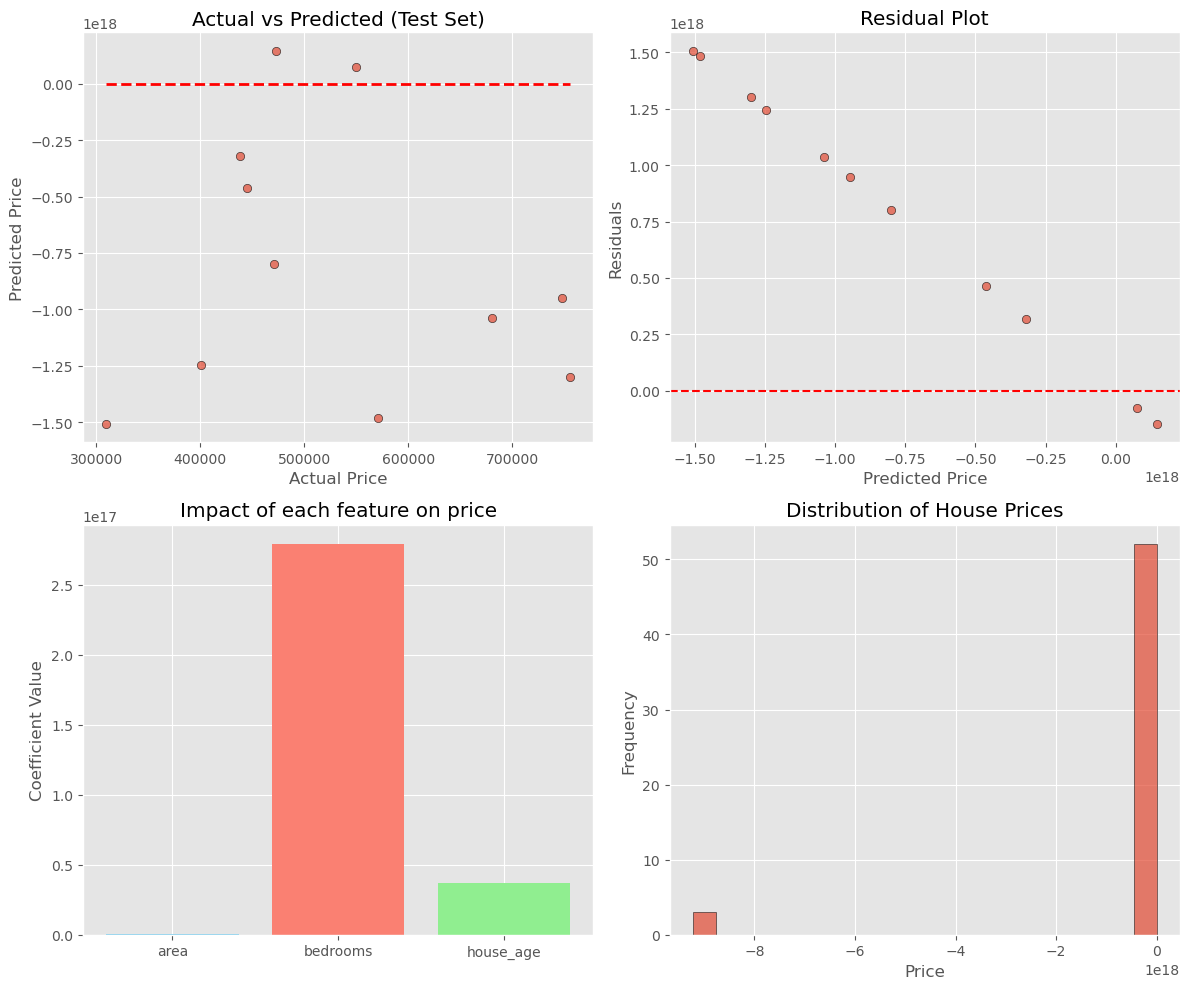


✅ Graphs saved as '2.P.1 home_price_plots.png'


In [91]:
# ============================================================
# 7. VISUALISATIONS (Graphs)
# ============================================================
plt.style.use('ggplot')
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# 7.1 Actual vs Predicted (test set)
axes[0,0].scatter(y_test, y_pred_test, alpha=0.7, edgecolors='k')
axes[0,0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0,0].set_xlabel("Actual Price")
axes[0,0].set_ylabel("Predicted Price")
axes[0,0].set_title("Actual vs Predicted (Test Set)")

# 7.2 Residual plot
residuals = y_test - y_pred_test
axes[0,1].scatter(y_pred_test, residuals, alpha=0.7, edgecolors='k')
axes[0,1].axhline(y=0, color='r', linestyle='--')
axes[0,1].set_xlabel("Predicted Price")
axes[0,1].set_ylabel("Residuals")
axes[0,1].set_title("Residual Plot")

# 7.3 Feature coefficients bar chart
coef_names = ['area', 'bedrooms', 'house_age']
coef_values = model.coef_
axes[1,0].bar(coef_names, coef_values, color=['skyblue', 'salmon', 'lightgreen'])
axes[1,0].set_ylabel("Coefficient Value")
axes[1,0].set_title("Impact of each feature on price")

# 7.4 Distribution of house prices
axes[1,1].hist(df['price'], bins=20, edgecolor='black', alpha=0.7)
axes[1,1].set_xlabel("Price")
axes[1,1].set_ylabel("Frequency")
axes[1,1].set_title("Distribution of House Prices")

plt.tight_layout()
plt.savefig("2.P.1 home_price_plots.png", dpi=150)
plt.show()
print("\n✅ Graphs saved as '2.P.1 home_price_plots.png'")

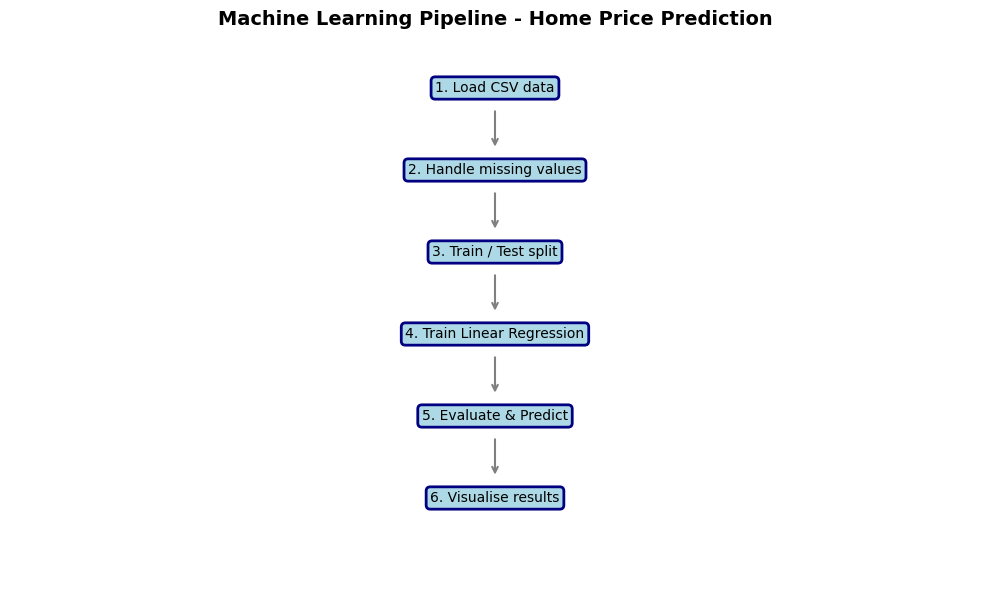

✅ Flowchart saved as '2.P.1 flowchart.png'


In [86]:
# ============================================================
# 8. FLOWCHART (using matplotlib patches)
# ============================================================
def draw_flowchart():
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 8)
    ax.axis('off')

    # Box style
    box_style = dict(boxstyle="round,pad=0.3", facecolor="lightblue", edgecolor="navy", linewidth=2)
    arrow_style = dict(arrowstyle="->", color="gray", lw=1.5)

    # Steps and positions
    steps = [
        ("1. Load CSV data", (5, 7.2)),
        ("2. Handle missing values", (5, 6.0)),
        ("3. Train / Test split", (5, 4.8)),
        ("4. Train Linear Regression", (5, 3.6)),
        ("5. Evaluate & Predict", (5, 2.4)),
        ("6. Visualise results", (5, 1.2))
    ]

    for text, (x, y) in steps:
        ax.text(x, y, text, ha='center', va='center', fontsize=10,
                bbox=box_style)

    # Draw arrows between steps
    for i in range(len(steps)-1):
        start = (steps[i][1][0], steps[i][1][1] - 0.3)
        end   = (steps[i+1][1][0], steps[i+1][1][1] + 0.3)
        ax.annotate("", xy=end, xytext=start, arrowprops=arrow_style)

    ax.set_title("Machine Learning Pipeline - Home Price Prediction", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig("2.P.1 flowchart.png", dpi=150, bbox_inches='tight')
    plt.show()

draw_flowchart()
print("✅ Flowchart saved as '2.P.1 flowchart.png'")
